# SAP RPT 1.6 TechEd hands-on — Part 2: explainability


This focused notebook constructs an SAP RPT 1.6 explainability request and interprets its two outputs: attention-derived column scores and ranked relevant context rows.

It is standalone: it prepares the used-car context and query rows itself. It does not repeat baseline evaluation or full-test-set inference from Part 1.

> These outputs describe model attention. They are not signed feature contributions or causal explanations.


## 0. Setup GenAIHub credentials and import packages

Import the required libraries

In [1]:
# Imports 
import os
from pathlib import Path
import io
import json
from typing import List, Dict, Tuple, Optional



import pandas as pd
import numpy as np
import requests
from IPython.display import display

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split



# Performance-friendly display
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

/Users/d067487/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


### Import the SAP RPT 1.6 API credentials from your `.env` file


Run the cell below to load the environment variables.

In [ ]:
from dotenv import load_dotenv

load_dotenv()
AICORE_AUTH_URL = os.getenv("AICORE_AUTH_URL")
AICORE_CLIENT_ID = os.getenv("AICORE_CLIENT_ID")
AICORE_CLIENT_SECRET = os.getenv("AICORE_CLIENT_SECRET")
AICORE_RESOURCE_GROUP = os.getenv("AICORE_RESOURCE_GROUP")
AICORE_BASE_URL = os.getenv("AICORE_BASE_URL")
RPT_DEPLOYMENT_ID = os.getenv("RPT_DEPLOYMENT_ID")
RPT_LARGE_DEPLOYMENT_ID = os.getenv("RPT_LARGE_DEPLOYMENT_ID")


### Configure the remote deployment

This configuration is required for either credential option. Enter the deployment ID assigned for the exercise.


In [ ]:
BASE_DEPLOYMENT_URL = f"{AICORE_BASE_URL}/v2/inference/deployments/"
DEPLOYMENTS = {
    "sap-rpt-1.6": RPT_DEPLOYMENT_ID,
    "sap-rpt-1.6-large": RPT_LARGE_DEPLOYMENT_ID,
}


In [5]:
def select_model(model_name: str) -> Tuple[str, int]:
    if model_name not in DEPLOYMENTS:
        raise ValueError(f"Invalid model name: {model_name}")
    deployment_id = DEPLOYMENTS[model_name]
    if not deployment_id or deployment_id.startswith("YOUR_"):
        raise ValueError(f"Configure the deployment ID for {model_name}")
    deployment_url = BASE_DEPLOYMENT_URL + deployment_id
    max_context_rows = 8_192 if model_name == "sap-rpt-1.6-large" else 2_048
    return deployment_url, max_context_rows


In [6]:
RPT_DEPLOYMENT_URL, MAX_CONTEXT_ROWS = select_model('sap-rpt-1.6')

## Setup and test the authentication with AI Core using your credentials 

In [ ]:
def get_access_token() -> str:
    assert all([AICORE_AUTH_URL, AICORE_CLIENT_ID, AICORE_CLIENT_SECRET]), (
        "Missing OAuth settings: AICORE_AUTH_URL, AICORE_CLIENT_ID, AICORE_CLIENT_SECRET"
    )
    resp = requests.post(
        f"{AICORE_AUTH_URL}/oauth/token",
        data={"grant_type": "client_credentials", "client_id": AICORE_CLIENT_ID, "client_secret": AICORE_CLIENT_SECRET},
        timeout=60,
    )
    resp.raise_for_status()
    return resp.json()["access_token"]

print("Access token generated; last four characters:", get_access_token()[-4:])


Access token generated; last four characters: 43YA


## 1. Load the explanation dataset


In [9]:
candidates = [
    Path("used_cars_24.csv"),  # Kernel started in the Notebooks directory
    Path("Notebooks/used_cars_24.csv"),  # Kernel started at the sap-rpt-enablement root
    Path("sap-rpt-enablement/Notebooks/used_cars_24.csv"),  # Kernel started at the workspace root
]
CSV_PATH = next((path for path in candidates if path.exists()), None)
assert CSV_PATH is not None, f"Dataset not found; checked {candidates}"
df = pd.read_csv(CSV_PATH)
assert len(df) > 0
print(f"Loaded rows: {len(df)}")
print(f"Columns: {df.columns.tolist()}")
df.head()


Loaded rows: 5918
Columns: ['idx', 'Car Brand', 'Model', 'Price', 'Model Year', 'Location', 'Fuel', 'Driven (Kms)', 'Gear', 'Ownership', 'EMI (monthly)']


,idx,Car Brand,Model,Price,Model Year,Location,Fuel,Driven (Kms),Gear,Ownership,EMI (monthly)
0,0,Hyundai,EonERA PLUS,330399,2016,Hyderabad,Petrol,10674,Manual,2,7350
1,1,Maruti,Wagon R 1.0LXI,350199,2011,Hyderabad,Petrol,20979,Manual,1,7790
2,2,Maruti,Alto K10LXI,229199,2011,Hyderabad,Petrol,47330,Manual,2,5098
3,3,Maruti,RitzVXI BS IV,306399,2011,Hyderabad,Petrol,19662,Manual,1,6816
4,4,Tata,NanoTWIST XTA,208699,2015,Hyderabad,Petrol,11256,Automatic,1,4642


## 2. Select the target

The target is retained as ground truth for evaluation, but replaced by the prediction placeholder in every query row sent to SAP RPT.


In [10]:
# Choose your target column 
TARGET_COLUMN = "Price" #"Fuel"

# Validate target column exists
assert TARGET_COLUMN in df.columns, f"Target column {TARGET_COLUMN} not found in dataset!"

print(f"Target column: {TARGET_COLUMN}")
print(f"Target distribution:\n{df[TARGET_COLUMN].value_counts().sort_index()}")
df[[TARGET_COLUMN]].head()

Target column: Price
Target distribution:
Price
91000      1
103599     1
105000     1
107000     1
107399     1
          ..
2724199    1
2976299    1
3495000    1
4100000    1
6500000    1
Name: count, Length: 4139, dtype: int64


,Price
0,330399
1,350199
2,229199
3,306399
4,208699


## 3. Define the task type

Price is numeric, so this exercise uses regression.


Task type: regression


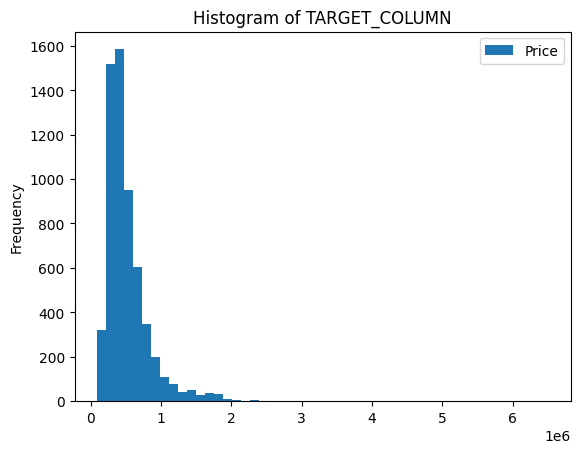

In [11]:
# Set task type explicitly: "regression" or "classification"
# For e.g. Price prediction, we use regression
TASK_TYPE = "regression" # "classification"

if TASK_TYPE == "regression":
    # Coerce target numeric where possible
    df[TARGET_COLUMN] = pd.to_numeric(df[TARGET_COLUMN], errors="coerce")
    df[[TARGET_COLUMN]].plot.hist(bins=50, title="Histogram of TARGET_COLUMN")
elif TASK_TYPE == "classification":
    # Treat as strings for classification
    df[TARGET_COLUMN] = df[TARGET_COLUMN].astype(str)
    df[TARGET_COLUMN].value_counts().sort_index().plot.bar(color='skyblue', alpha=0.75, title='Value Counts of TARGET_COLUMN')
else:
    raise ValueError(f"Unknown TASK_TYPE: {TASK_TYPE}")

print(f"Task type: {TASK_TYPE}")

## 4. Remove leakage and identifiers

Explanation quality is meaningless when a target-derived field or arbitrary row identifier is passed as a feature.


In [12]:
# Remove target leakage and row identifiers that should not become model features.
LEAKER_COLUMNS: List[str] = ["EMI (monthly)"]
IDENTIFIER_COLUMNS: List[str] = ["idx"]
excluded_columns = [
    column for column in LEAKER_COLUMNS + IDENTIFIER_COLUMNS if column in df.columns
]
df_clean = df.drop(columns=excluded_columns).copy()
print(f"Excluded non-feature columns: {excluded_columns}")
print(f"Remaining columns: {df_clean.columns.tolist()}")
df_clean.head()


Excluded non-feature columns: ['EMI (monthly)', 'idx']
Remaining columns: ['Car Brand', 'Model', 'Price', 'Model Year', 'Location', 'Fuel', 'Driven (Kms)', 'Gear', 'Ownership']


,Car Brand,Model,Price,Model Year,Location,Fuel,Driven (Kms),Gear,Ownership
0,Hyundai,EonERA PLUS,330399,2016,Hyderabad,Petrol,10674,Manual,2
1,Maruti,Wagon R 1.0LXI,350199,2011,Hyderabad,Petrol,20979,Manual,1
2,Maruti,Alto K10LXI,229199,2011,Hyderabad,Petrol,47330,Manual,2
3,Maruti,RitzVXI BS IV,306399,2011,Hyderabad,Petrol,19662,Manual,1
4,Tata,NanoTWIST XTA,208699,2015,Hyderabad,Petrol,11256,Automatic,1


## 5. Create context and query pools

The train split supplies candidate context rows. The held-out split supplies query rows whose known prices are used only as ground truth.


In [13]:
# Simple, readable split strategy
TEST_SIZE = 0.2
SORTING_COLUMN: Optional[str] = None

# Rows without ground truth cannot be evaluated. Feature nulls remain null for the service.
df_model = df_clean.dropna(subset=[TARGET_COLUMN]).copy()
if SORTING_COLUMN:
    assert SORTING_COLUMN in df_model.columns
    df_sorted = df_model.sort_values(by=SORTING_COLUMN)
    n_test = max(1, int(len(df_sorted) * TEST_SIZE))
    df_train, df_test = df_sorted.iloc[:-n_test], df_sorted.iloc[-n_test:]
else:
    stratify = df_model[TARGET_COLUMN] if TASK_TYPE == "classification" else None
    df_train, df_test = train_test_split(df_model, test_size=TEST_SIZE, random_state=42, stratify=stratify)
assert len(df_train) > 0 and len(df_test) > 0
FEATURE_COLUMNS = [column for column in df_model.columns if column != TARGET_COLUMN]
X_train = df_train[FEATURE_COLUMNS].copy()
y_train = df_train[TARGET_COLUMN].copy()
X_test = df_test[FEATURE_COLUMNS].copy()
y_test = df_test[TARGET_COLUMN].copy()
print(f"Train: {len(X_train)} rows, Test: {len(X_test)} rows, Features: {len(FEATURE_COLUMNS)}")
print(f"Feature columns: {FEATURE_COLUMNS}")


Train: 4734 rows, Test: 1184 rows, Features: 8
Feature columns: ['Car Brand', 'Model', 'Model Year', 'Location', 'Fuel', 'Driven (Kms)', 'Gear', 'Ownership']


## 6. Select context rows

The context contains examples with known prices. Changing this context can change both predictions and explanations.


In [ ]:
# MAX_CONTEXT_ROWS was set when selecting the SAP RPT 1.6 endpoint.
X_context = X_train.sample(n=min(MAX_CONTEXT_ROWS, len(X_train)), random_state=42)
y_context = y_train.loc[X_context.index]
print(f"Context rows: {len(X_context)}")

# The following snipplet only necessary to prepare exercise 3 (Tabular AI orchestration) 
# For this exercise, we need the data to be splitted into 2 csv files: query and context 
context_rows = pd.concat([X_train, y_train], axis=1)
query_rows = pd.concat([X_test, y_test], axis=1)
context_rows.to_csv('used_cars_24_context.csv', index=False)
query_rows.to_csv('used_cars_24_query.csv', index=False)

Context rows: 2048


## 7. Build the request table

SAP RPT receives context and query rows in one table. Context rows keep their known target; query rows receive the prediction placeholder. A synthetic index column supports response alignment and is excluded as a model feature.


In [15]:
RPT_PREDICTION_PLACEHOLDER = "[PREDICT]"
MAX_QUERY_ROWS = 128


def to_python_type(val):
    """Convert numpy/pandas types to native Python types for JSON serialization."""
    if isinstance(val, (np.integer, np.floating)):
        return val.item()
    if isinstance(val, np.ndarray):
        return val.tolist()
    if isinstance(val, pd.Timestamp):
        return val.strftime('%Y-%m-%d')
    if pd.isna(val):
        return None
    return val


def build_rows(X_context: pd.DataFrame, y_context: pd.Series, X_query: pd.DataFrame) -> List[Dict]:
    rows: List[Dict] = []
    # Context rows with actual target
    for i, (_, row) in enumerate(X_context.iterrows()):
        rd = {k: to_python_type(v) for k, v in row.to_dict().items()}
        rd[TARGET_COLUMN] = to_python_type(y_context.iloc[i])
        rd["__row_idx__"] = f"1{i:06d}"
        rows.append(rd)
    # Query rows with placeholder
    for i, (_, row) in enumerate(X_query.iterrows()):
        rd = {k: to_python_type(v) for k, v in row.to_dict().items()}
        rd[TARGET_COLUMN] = RPT_PREDICTION_PLACEHOLDER
        rd["__row_idx__"] = f"2{i:06d}"
        rows.append(rd)
    return rows

In [ ]:
def call_rpt_predict(payload: Dict, access_token: str) -> Dict:
    assert RPT_DEPLOYMENT_URL, "RPT_DEPLOYMENT_URL must be set to call the API"
    url = f"{RPT_DEPLOYMENT_URL}/predict"
    headers = {
        "Content-Type": "application/json",
        "Authorization": f"Bearer {access_token}",
        "ai-resource-group": AICORE_RESOURCE_GROUP,
    }
    response = requests.post(url, headers=headers, json=payload, timeout=300)
    try:
        result = response.json()
    except ValueError as exc:
        raise RuntimeError(f"Non-JSON response (HTTP {response.status_code}): {response.text[:1000]}") from exc
    if not response.ok:
        raise RuntimeError(f"HTTP {response.status_code}: {json.dumps(result, indent=2)}")
    status = result.get("status", {})
    if status.get("code", 3) >= 2:
        raise RuntimeError(f"Prediction failed: {json.dumps(result, indent=2)}")
    if status.get("code") == 1:
        print(f"Serving warning: {status.get('message')}")
    return result


## 8. Construct and send the explainability payload

The payload has four important parts:

1. target_columns identifies the target, placeholder, and task type.
2. explanations.top_column_scores requests up to k column scores per query.
3. explanations.top_relevant_context_rows requests up to k ranked context-row positions per query.
4. rows contains the exact combined context/query table retained for later index lookup.

Both explanation limits accept values from 0 through 20. Zero disables that output.


### Inspect the payload before sending it

The next cell builds the complete payload. Notice that explanations belongs inside prediction_config, while rows and index_column remain top-level request fields. The response explanation arrays will follow query-row order.


In [18]:
TOP_COLUMN_SCORES = min(8, len(FEATURE_COLUMNS))
TOP_RELEVANT_CONTEXT_ROWS = 5
EXPLANATION_QUERY_ROWS = min(8, len(X_test))
X_explain = X_test.iloc[:EXPLANATION_QUERY_ROWS].copy()
y_explain = y_test.loc[X_explain.index].copy()
explanation_rows = build_rows(X_context, y_context, X_explain)
explanation_payload = {
    "prediction_config": {
        "target_columns": [{
            "name": TARGET_COLUMN,
            "prediction_placeholder": RPT_PREDICTION_PLACEHOLDER,
            "task_type": TASK_TYPE,
        }],
        "explanations": {
            "top_column_scores": TOP_COLUMN_SCORES,
            "top_relevant_context_rows": TOP_RELEVANT_CONTEXT_ROWS,
        },
    },
    "index_column": "__row_idx__",
    "rows": explanation_rows,
}
print("Explanation configuration:")
print(json.dumps(explanation_payload["prediction_config"], indent=2))
print(f"Submitted rows: {len(explanation_rows)} = {len(X_context)} context + {len(X_explain)} query")

explanation_response = call_rpt_predict(explanation_payload, get_access_token())
explanations = explanation_response.get("explanations")
assert explanations is not None, "No explanations returned; confirm that explainability is enabled."
print(json.dumps(explanation_response["metadata"], indent=2))


Explanation configuration:
{
  "target_columns": [
    {
      "name": "Price",
      "prediction_placeholder": "[PREDICT]",
      "task_type": "regression"
    }
  ],
  "explanations": {
    "top_column_scores": 8,
    "top_relevant_context_rows": 5
  }
}
Submitted rows: 2056 = 2048 context + 8 query
{
  "context_mode": "default",
  "num_columns": 10,
  "num_predictions": 8,
  "num_query_rows": 8,
  "num_rows": 2056
}


### 8.1 Align predictions and explanations

Predictions and both explanation arrays follow query-row order. The synthetic IDs make the alignment explicit.


In [19]:
prediction_items = explanation_response["predictions"]
column_scores = explanations.get("top_column_scores")
relevant_context_rows = explanations.get("top_relevant_context_rows")
assert len(prediction_items) == len(X_explain)
assert column_scores is not None and len(column_scores) == len(X_explain)
assert relevant_context_rows is not None and len(relevant_context_rows) == len(X_explain)
expected_ids = [f"2{i:06d}" for i in range(len(X_explain))]
assert [item["__row_idx__"] for item in prediction_items] == expected_ids
explanation_summary = X_explain.copy()
explanation_summary.insert(0, "source_row_index", X_explain.index)
explanation_summary["ground_truth"] = y_explain.to_numpy()
explanation_summary["prediction"] = [item[TARGET_COLUMN][0]["prediction"] for item in prediction_items]
explanation_summary["top_attended_column"] = [max(scores, key=scores.get) for scores in column_scores]
display(explanation_summary)


,source_row_index,Car Brand,Model,Model Year,Location,Fuel,Driven (Kms),Gear,Ownership,ground_truth,prediction,top_attended_column
1535,1535,Maruti,SwiftVDI,2014,Delhi,Diesel,117196,Manual,1,328599,385175.3750,Model
2302,2302,Volkswagen,PoloGT TSI,2018,Delhi,Petrol,43872,Manual,1,716799,801929.7500,Model
1197,1197,Maruti,Swift DzireVDI BS IV,2013,Delhi,Diesel,79248,Manual,2,358699,386118.8750,Model
5057,5057,Maruti,ErtigaZDI,2014,Bangalore,Diesel,94656,Manual,3,676199,630739.6250,Model
5793,5793,Volkswagen,VentoHIGHLINE TDI AT,2015,Chennai,Diesel,90897,Automatic,2,644199,566454.5625,Location
4691,4691,Hyundai,i10SPORTZ 1.2 KAPPA2,2011,Bangalore,Petrol,31738,Manual,1,404499,380411.6875,Location
3897,3897,Hyundai,EonMAGNA PLUS,2016,Mumbai,Petrol,59113,Manual,1,324699,318625.3750,Model
5590,5590,Maruti,CelerioVXI,2018,Chennai,Petrol,53793,Manual,1,458199,470309.1875,Model


### 8.2 Compare column scores

Missing cells mean a column did not enter that query's returned top-k list. Zero is used below only for visualization, so the mean is descriptive rather than global feature importance.


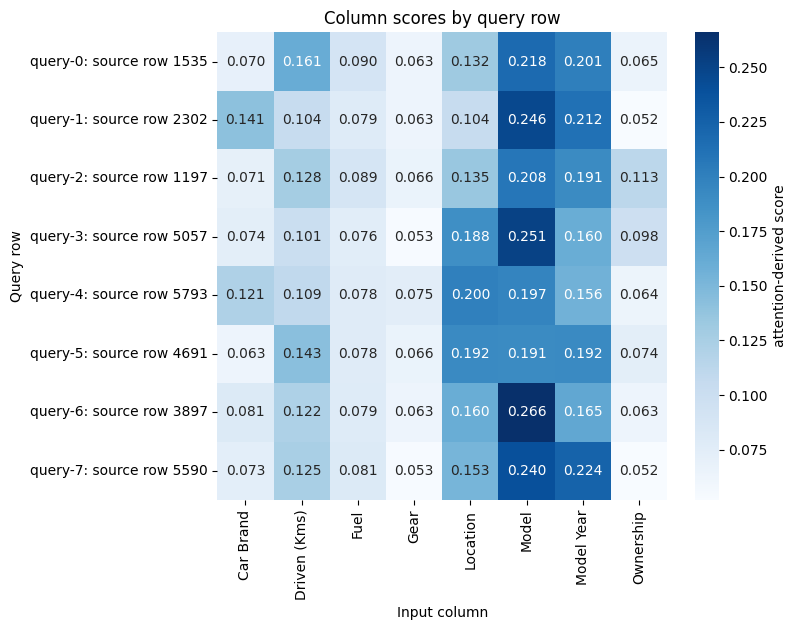

,mean returned score
Model,0.227125
Model Year,0.187625
Location,0.158000
Driven (Kms),0.124125
Car Brand,0.086750
Fuel,0.081250
Ownership,0.072625
Gear,0.062750


In [20]:
query_labels = [f"query-{i}: source row {idx}" for i, idx in enumerate(X_explain.index)]
column_score_frame = pd.DataFrame(column_scores, index=query_labels).fillna(0.0)
plt.figure(figsize=(max(8, 0.8 * len(column_score_frame.columns)), 0.55 * len(column_score_frame) + 2))
sns.heatmap(column_score_frame, annot=True, fmt=".3f", cmap="Blues", cbar_kws={"label": "attention-derived score"})
plt.title("Column scores by query row")
plt.xlabel("Input column")
plt.ylabel("Query row")
plt.tight_layout()
plt.show()
display(column_score_frame.mean().sort_values(ascending=False).rename("mean returned score").to_frame())


### 8.3 Inspect a prediction and its context rows

Choose a query position. Returned row indices are zero-based positions in the full request, so retain the exact submitted table when resolving them.


In [36]:
SELECTED_QUERY_POSITION = 4
assert 0 <= SELECTED_QUERY_POSITION < len(X_explain)
selected_indices = relevant_context_rows[SELECTED_QUERY_POSITION]
assert all(0 <= index < len(explanation_rows) for index in selected_indices)
selected_context = pd.DataFrame([explanation_rows[index] for index in selected_indices], index=selected_indices)
selected_context.index.name = "request_row_position"
selected_context.insert(0, "relevance_rank", range(1, len(selected_context) + 1))
selected_scores = pd.Series(column_scores[SELECTED_QUERY_POSITION], name="score").sort_values(ascending=False)
print("Query and prediction")
display(explanation_summary.iloc[[SELECTED_QUERY_POSITION]])
print("Top column scores")
display(selected_scores.to_frame())
print("Most relevant context rows")
display(selected_context)


Query and prediction


,source_row_index,Car Brand,Model,Model Year,Location,Fuel,Driven (Kms),Gear,Ownership,ground_truth,prediction,top_attended_column
5793,5793,Volkswagen,VentoHIGHLINE TDI AT,2015,Chennai,Diesel,90897,Automatic,2,644199,566454.5625,Location


Top column scores


,score
Location,0.200
Model,0.197
Model Year,0.156
Car Brand,0.121
Driven (Kms),0.109
Fuel,0.078
Gear,0.075
Ownership,0.064


Most relevant context rows


,relevance_rank,Car Brand,Model,Model Year,Location,Fuel,Driven (Kms),Gear,Ownership,Price,__row_idx__
request_row_position,,,,,,,,,,,
1569,1,Volkswagen,VentoHIGHLINE TDI AT,2015,Bangalore,Diesel,112010,Automatic,1,640899,1001569
902,2,Volkswagen,VentoHIGHLINE TDI AT,2015,Delhi,Diesel,48299,Automatic,2,550000,1000902
1453,3,Volkswagen,VentoHIGHLINE TDI AT,2015,Mumbai,Diesel,103483,Automatic,1,547499,1001453
688,4,Volkswagen,VentoHIGHLINE TDI AT,2016,Mumbai,Diesel,123078,Automatic,1,618799,1000688
722,5,Volkswagen,PoloHIGHLINE1.5L DIESEL,2014,Chennai,Diesel,170685,Manual,2,363599,1000722


### 8.4 Discuss

1. Does the highest-scoring column make domain sense?
2. How are the top context cars similar to the query car?
3. Does high attention prove that changing a column changes the prediction? Why not?
4. Would you trust the explanation equally when prediction confidence band is large?


## 9. Optional Follow-up tasks: Evaluate & Iterate

- Both model predictions and explanations depend on context. Keeps one query fixed and vary the context size provided to the model. Enable it only when instructed to control workshop latency.


## 10. Takeaways

- SAP RPT 1.6 learns from context supplied with each request; it is not trained here.
- Explainability is opt-in for column scores and context-row rankings.
- Attention signals are not signed attributions or causal evidence.
- Stable IDs and the exact request table are essential for interpreting returned row indices.

If time permits, compare an accurate and inaccurate prediction, remove a highly attended column and reevaluate, or enter your own car.
